In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Ellipse
from matplotlib.backends.backend_pdf import PdfPages 

## Building Base Map

In [18]:
statefp = "20"

# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


## code for county level data 

counties = gpd.read_file(url_0+url_county)
state_counties = counties.loc[counties["STATEFP"] == statefp].copy()
state_counties = state_counties.sort_values("NAME").reset_index(drop=True)

In [3]:
# function with county and ax being the parameter

def county_map(county, ax):
    selected = state_counties[state_counties["NAME"] == county]
    selected.plot(ax=ax, edgecolor="black", facecolor="forestgreen")
    ax.set_axis_off()


def locator_map(county, ax):
    selected = state_counties[state_counties["NAME"] == county]
    state_counties.plot(ax=ax, edgecolor="gray", facecolor="white")
    selected.plot(ax=ax, edgecolor="black", facecolor="forestgreen")
    ax.set_axis_off()

## Renewable Counts

### Wind

#### State-level Counts

In [6]:
# Read data

wind = gpd.read_file("wind energy/data/wind_turbines.geojson")
wind = wind.to_crs(epsg=4269)
wind = wind[["t_state","p_name","geometry"]].copy()

# spatial join

wind_by_county = gpd.sjoin(wind, state_counties, predicate='within')

In [7]:
# wind count in each county

wind_count = wind_by_county["NAME"].value_counts()

In [8]:
# creating new table

wind_count_table = wind_count.reset_index()
wind_count_table.columns = ["NAME", "Wind Turbines"]
wind_count_table

,NAME,Wind Turbines
0,Ford,464
1,Gray,342
2,Clark,284
3,Kingman,284
4,Pratt,227
5,Harper,203
6,Republic,202
7,Sumner,184
8,Thomas,177
9,Marion,171


In [9]:
# add new column

final_wind_count = state_counties.merge(wind_count_table, on="NAME", how="left")
final_wind_count["Wind Turbines"] = final_wind_count["Wind Turbines"].fillna(0)
final_wind_count["Wind Turbines"] = final_wind_count["Wind Turbines"].astype(int)

# filtering for only needed columns

final_wind_count = final_wind_count[["NAME", "geometry", "Wind Turbines"]].copy()
final_wind_count

,NAME,geometry,Wind Turbines
0,Allen,"POLYGON ((-95.52522 37.74734, -95.52484 37.761...",59
1,Anderson,"POLYGON ((-95.51873 38.10372, -95.5181 38.1399...",0
2,Atchison,"POLYGON ((-95.57026 39.47701, -95.57014 39.505...",0
3,Barber,"POLYGON ((-99.0126 37.47042, -99.00038 37.4705...",92
4,Barton,"POLYGON ((-99.0327 38.43501, -99.03298 38.4785...",0
...,...,...,...
100,Washington,"POLYGON ((-97.3692 39.92226, -97.36922 39.9258...",32
101,Wichita,"POLYGON ((-101.56709 38.69967, -101.48438 38.7...",33
102,Wilson,"POLYGON ((-95.9626 37.41777, -95.96217 37.4237...",0
103,Woodson,"POLYGON ((-95.96141 37.82198, -95.95813 37.821...",0


#### Plotting

In [10]:
# Selecting needed columns
wind_points = wind_by_county[["p_name","geometry"]].copy()

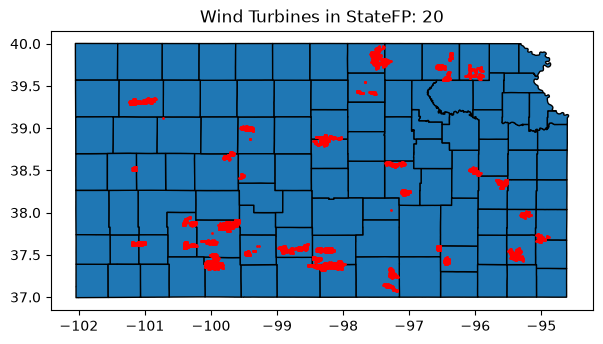

In [22]:
# Plotting wind turbines NC
fig, ax = plt.subplots(figsize=(7,7))
state_counties.plot(ax=ax, edgecolor="black")
wind_points.plot(ax=ax, markersize=1, c="red")
ax.set_title(f"Wind Turbines in StateFP: {statefp}")
plt.show()

## Map Features

In [ ]:
# Making a pie chart function
def county_pie(county, ax):
    selected = state_counties[state_counties["NAME"] == county]

    land = selected["ALAND"].iloc[0]
    water = selected["AWATER"].iloc[0]

    ax.pie(
        [land, water],
        labels=["Land", "Water"],
        colors=["olivedrab", "steelblue"],
        autopct="%.1f%%",
        startangle=90
    )

    ax.set_title("Land and water")

In [ ]:
def county_info(county, ax):
    selected = state_counties[state_counties["NAME"] == county]

    land = selected["ALAND"].iloc[0]
    water = selected["AWATER"].iloc[0]

    ## Using ai and https://matplotlib.org/stable/gallery/shapes_and_collections/hatch_demo.html
    # Land icon: mountains
    mountain = Polygon(
        [(0.02, 0.60), (0.09, 0.80), (0.14, 0.69),
         (0.19, 0.76), (0.25, 0.60)],
        facecolor="olivedrab",
        transform=ax.transAxes
    )
    ax.add_patch(mountain)

    # Water icon
    lake = Ellipse(
        (0.13, 0.30),
        width=0.23,
        height=0.12,
        facecolor="steelblue",
        transform=ax.transAxes
    )
    ax.add_patch(lake)

    ax.text(
        0.32, 0.80,
        f"LAND\n{land / 1_000_000:,.2f} km²\n"
        f"{land / 2_589_988.110336:,.2f} square miles",
        transform=ax.transAxes,
        fontsize=14,
        color="olivedrab",
        va="top"
    )

    ax.text(
        0.32, 0.40,
        f"WATER\n{water / 1_000_000:,.2f} km²\n"
        f"{water / 2_589_988.110336:,.2f} square miles",
        transform=ax.transAxes,
        fontsize=14,
        color="steelblue",
        va="top"
    )

    ax.set_axis_off()

In [ ]:
#Let's make it a function

def county_figure(county, pdf):

    fig = plt.figure(figsize=(12, 8))

    # [left, bottom, width, height] as fractions of the figure
    # Coded with Ai help
    ax_county = fig.add_axes([0.05, 0.23, 0.55, 0.54])
    ax_locator = fig.add_axes([0.05, 0.08, 0.25, 0.12])
    ax_pie = fig.add_axes([0.65, 0.48, 0.30, 0.30])
    ax_info = fig.add_axes([0.65, 0.12, 0.30, 0.32])


    county_map(county, ax_county)
    locator_map(county, ax_locator)
    county_pie(county, ax_pie)
    county_info(county, ax_info)

    # Page heading
    fig.text(
        0.05, 0.94,
        statefp + " / County Water-Land Atlas",
        fontsize=10,
        color="olivedrab"
    )

    fig.text(
        0.05, 0.87,
        f"{county} County",
        fontsize=28,
        fontweight="bold"
    )

    # Footer
    fig.text(
        0.05, 0.03,
        "Source: U.S. Census Bureau | Areas from ALAND and AWATER",
        fontsize=9,
        color="gray"
    )

    pdf.savefig(fig)
    plt.close(fig)


In [ ]:
pdfname = statefp + ".pdf"
# This might take a few seconds and you need at least 40MB of free space in your computer
with PdfPages(pdfname) as pdf:  #with #manages a resource and automatically cleans up when you finish using it.
    for county in state_counties["NAME"]:
        county_figure(county, pdf)

In [ ]:
%pip install nbconvert
# python3 -m nbconvert --to script "GEOG592_JN_to_py.ipynb"